# Stage 4B: final held-out MNIST evaluation

Recover **27 preselected ticket checkpoints**, verify them and **18 saved controls**, then evaluate the 45 selected states on the 10,000-image test set. Original experiment artifacts are read-only. No new checkpoint selection, pruning, or hyperparameter changes use test results.

Run from the repository root with the project Python environment. The spawn-safe runner works with pathlib on Windows/macOS; exact historical numerical replay is checked rather than assumed across software/platforms. Completed replay/test artifacts are reused. All outputs go to `reports/stage4_test/`.

In [1]:
import os,sys,json,subprocess,tempfile,time
from pathlib import Path
os.environ.setdefault('MPLCONFIGDIR',str(Path(tempfile.gettempdir())/'lottery-stage4-mpl'))
import pandas as pd
from IPython.display import display,Image,Markdown
from tqdm.auto import tqdm
from stage4_test_runner import ROOT,REPORT,TICKETS,require_gate,preserve_previous
REPORT.mkdir(parents=True,exist_ok=True)
status=REPORT/'execution.json'
if not status.exists() or json.loads(status.read_text()).get('status')!='complete':
    with (REPORT/'notebook_execution.log').open('w') as log:
        process=subprocess.Popen([sys.executable,str(ROOT/'stage4_test_runner.py'),'--workers','3'],cwd=ROOT,stdout=log,stderr=subprocess.STDOUT)
        with tqdm(total=27,desc='Verified ticket replays',unit='ticket') as progress:
            while process.poll() is None:
                completed=len(list((REPORT/'replays').glob('*/verified.json')))
                progress.update(max(0,completed-progress.n))
                time.sleep(1)
            if process.returncode: raise RuntimeError((REPORT/'notebook_execution.log').read_text())
            progress.update(27-progress.n)
display(json.loads(status.read_text()))
gate=json.loads((REPORT/'validation_gate.json').read_text())
require_gate(gate['records'])
display(pd.read_csv(REPORT/'checkpoint_verification.csv'))
display(json.loads((REPORT/'protocol.lock.json').read_text()))

{'status': 'complete',
 'ticket_replays': 27,
 'controls': 18,
 'test_models': 45,
 'previous_files_unchanged': 1268,
 'runtime_seconds': 252.32491461100108}

,architecture,seed,stage,condition,selected_iteration,validation_loss,validation_accuracy,loss_absolute_difference,accuracy_absolute_difference,total_weights,remaining_weights,remaining_percent,sparsity,parameters,remaining_parameters,parameter_sparsity,checkpoint,checkpoint_sha256,mask_sha256,verified
0,A,0,0,original_initialization,2500,0.075865,0.9786,4.163336e-17,0.0,199420,199420,100.000000,0.000000,200013,200013,0.000000,reports/stage4_test/replays/A_seed0_round0/bes...,194481991b16a0c1dc73a3e7ee33f78c75497743870f9f...,363e390a3c1fec69d69c29a4d05739a311838b43346709...,True
1,A,0,6,original_initialization,2600,0.065540,0.9810,2.775558e-17,0.0,199420,53415,26.785177,0.732148,200013,54008,0.729978,reports/stage4_test/replays/A_seed0_round6/bes...,e8eea999b463da1b867700d59a952d6ef98f29eec2a0c6...,501c1a39c558a879b764be86ff4ede6f39b12df4837ad3...,True
2,A,0,12,original_initialization,3300,0.069222,0.9794,4.163336e-17,0.0,199420,14610,7.326246,0.926738,200013,15203,0.923990,reports/stage4_test/replays/A_seed0_round12/be...,cfa1a08a8ab27f79a071d2e38050b578901b2714e95ce2...,4660d996f6258340503db8f43e99714214874b4f5bd121...,True
3,A,1,0,original_initialization,4700,0.078812,0.9792,1.387779e-17,0.0,199420,199420,100.000000,0.000000,200013,200013,0.000000,reports/stage4_test/replays/A_seed1_round0/bes...,5165037985919264af342ad1b8147557420d11a575234f...,363e390a3c1fec69d69c29a4d05739a311838b43346709...,True
4,A,1,6,original_initialization,2300,0.066295,0.9802,0.000000e+00,0.0,199420,53415,26.785177,0.732148,200013,54008,0.729978,reports/stage4_test/replays/A_seed1_round6/bes...,2cfc62adea51416d76dfef22eab19447631e7f7b15677e...,78baaafb4d99dc039059c696681e0f1e992bdc4609eddb...,True
5,A,1,12,original_initialization,2700,0.067542,0.9794,4.163336e-17,0.0,199420,14610,7.326246,0.926738,200013,15203,0.923990,reports/stage4_test/replays/A_seed1_round12/be...,5571a9dbe1a37ea3b3bc900d6f96e529fc2f51bd88d82a...,6ee341791d5fe810774380859de180c93f82c5e12545e9...,True
6,A,2,0,original_initialization,5700,0.077313,0.9802,8.326673e-17,0.0,199420,199420,100.000000,0.000000,200013,200013,0.000000,reports/stage4_test/replays/A_seed2_round0/bes...,e72140354868bf942e3f4fd5752ab74ae3ebe99a5c4599...,363e390a3c1fec69d69c29a4d05739a311838b43346709...,True
7,A,2,6,original_initialization,1900,0.065683,0.9788,1.387779e-17,0.0,199420,53415,26.785177,0.732148,200013,54008,0.729978,reports/stage4_test/replays/A_seed2_round6/bes...,35a4e54849c7f5306111213cec6af4e23ed0ebe38a1690...,4a8506a00eda280ede54ee5958c885620e6180822c9a60...,True
8,A,2,12,original_initialization,2500,0.071256,0.9792,4.163336e-17,0.0,199420,14610,7.326246,0.926738,200013,15203,0.923990,reports/stage4_test/replays/A_seed2_round12/be...,1b24368c3fb4b5db64a11de24590c909e96f37a1159a74...,ddb3e1ae179d4581e582eeac12b350695da670df589657...,True
9,B,0,0,original_initialization,4100,0.075284,0.9780,2.775558e-17,0.0,199640,199640,100.000000,0.000000,200054,200054,0.000000,reports/stage4_test/replays/B_seed0_round0/bes...,965bd68d239c9992c1640d529c61db4480d35196718212...,709e6c4ea39ff7e9e6814fc745cd259d180a6f9f55d52a...,True


{'ticket_cases': [['A', 0, 0],
  ['A', 0, 6],
  ['A', 0, 12],
  ['A', 1, 0],
  ['A', 1, 6],
  ['A', 1, 12],
  ['A', 2, 0],
  ['A', 2, 6],
  ['A', 2, 12],
  ['B', 0, 0],
  ['B', 0, 6],
  ['B', 0, 12],
  ['B', 1, 0],
  ['B', 1, 6],
  ['B', 1, 12],
  ['B', 2, 0],
  ['B', 2, 6],
  ['B', 2, 12],
  ['C', 0, 0],
  ['C', 0, 6],
  ['C', 0, 12],
  ['C', 1, 0],
  ['C', 1, 6],
  ['C', 1, 12],
  ['C', 2, 0],
  ['C', 2, 6],
  ['C', 2, 12]],
 'control_cases': [['A', 0, 6],
  ['A', 0, 12],
  ['A', 1, 6],
  ['A', 1, 12],
  ['A', 2, 6],
  ['A', 2, 12],
  ['B', 0, 6],
  ['B', 0, 12],
  ['B', 1, 6],
  ['B', 1, 12],
  ['B', 2, 6],
  ['B', 2, 12],
  ['C', 0, 6],
  ['C', 0, 12],
  ['C', 1, 6],
  ['C', 1, 12],
  ['C', 2, 6],
  ['C', 2, 12]],
 'loss_absolute_tolerance': 1e-08,
 'accuracy_absolute_tolerance': 1e-12,
 'selection': 'Stage 3/4A recorded minimum validation loss, no new selection',
 'replay_budget': 'Only until previously selected iteration, no mask generation',
 'training': {'learning_rate': 0.0012

## Observed-stage held-out results

Only stages **0, 6, 12** are measured here. Earlier 16k/20k validation interpolations are not measured test models. Accuracy changes use each architecture/seed's own original dense baseline. Paired differences are calculated before mean and **sample SD (n=3)**; SD bars are not confidence intervals.

,architecture,seed,stage,condition,selected_iteration,test_accuracy,test_accuracy_change_pp,remaining_parameters,sparsity,parameter_sparsity
0,A,0,0,original_initialization,2500,0.9780,0.00,200013,0.000000,0.000000
1,A,0,6,original_initialization,2600,0.9818,0.38,54008,0.732148,0.729978
2,A,0,12,original_initialization,3300,0.9823,0.43,15203,0.926738,0.923990
3,A,1,0,original_initialization,4700,0.9795,0.00,200013,0.000000,0.000000
4,A,1,6,original_initialization,2300,0.9820,0.25,54008,0.732148,0.729978
5,A,1,12,original_initialization,2700,0.9808,0.13,15203,0.926738,0.923990
6,A,2,0,original_initialization,5700,0.9802,0.00,200013,0.000000,0.000000
7,A,2,6,original_initialization,1900,0.9813,0.11,54008,0.732148,0.729978
8,A,2,12,original_initialization,2500,0.9812,0.10,15203,0.926738,0.923990
9,B,0,0,original_initialization,4100,0.9788,0.00,200054,0.000000,0.000000


,architecture,stage,condition,test_accuracy_mean,test_accuracy_std,test_accuracy_min,test_accuracy_max,test_loss_mean,test_loss_std,test_loss_min,test_loss_max,test_accuracy_change_pp_mean,test_accuracy_change_pp_std,test_accuracy_change_pp_min,test_accuracy_change_pp_max,validation_accuracy_mean,validation_accuracy_std,validation_accuracy_min,validation_accuracy_max,validation_accuracy_change_pp_mean,validation_accuracy_change_pp_std,validation_accuracy_change_pp_min,validation_accuracy_change_pp_max,selected_iteration_mean,selected_iteration_std,selected_iteration_min,selected_iteration_max,seed_count,remaining_parameters,remaining_weights,sparsity,parameter_sparsity,parameters
0,A,0,original_initialization,0.979233,0.001124,0.9780,0.9802,0.071786,0.002881,0.068658,0.074331,0.000000,0.000000,0.00,0.00,0.979333,0.000808,0.9786,0.9802,0.000000e+00,0.000000,0.00,0.00,4300.000000,1637.070554,2500,5700,3,200013,199420,0.000000,0.000000,200013
1,A,6,original_initialization,0.981700,0.000361,0.9813,0.9820,0.059427,0.001979,0.057238,0.061089,0.246667,0.135031,0.11,0.38,0.980000,0.001114,0.9788,0.9810,6.666667e-02,0.192180,-0.14,0.24,2266.666667,351.188458,1900,2600,3,54008,53415,0.732148,0.729978,200013
2,A,6,random_reinitialization,0.979800,0.001127,0.9785,0.9805,0.067275,0.001670,0.066174,0.069197,0.056667,0.177858,-0.10,0.25,0.979067,0.000757,0.9782,0.9796,-2.666667e-02,0.110151,-0.10,0.10,7066.666667,1965.536398,4800,8300,3,54008,53415,0.732148,0.729978,200013
3,A,12,original_initialization,0.981433,0.000777,0.9808,0.9823,0.059378,0.000903,0.058515,0.060317,0.220000,0.182483,0.10,0.43,0.979333,0.000115,0.9792,0.9794,3.700743e-15,0.091652,-0.10,0.08,2833.333333,416.333200,2500,3300,3,15203,14610,0.926738,0.923990,200013
4,A,12,random_reinitialization,0.975700,0.000693,0.9749,0.9761,0.079234,0.003700,0.076252,0.083375,-0.353333,0.051316,-0.41,-0.31,0.973333,0.002318,0.9718,0.9760,-6.000000e-01,0.249800,-0.80,-0.32,9400.000000,435.889894,9100,9900,3,15203,14610,0.926738,0.923990,200013
5,B,0,original_initialization,0.978500,0.001179,0.9772,0.9795,0.078237,0.008208,0.072949,0.087693,0.000000,0.000000,0.00,0.00,0.977933,0.001102,0.9768,0.9790,0.000000e+00,0.000000,0.00,0.00,5033.333333,3106.981386,2500,8500,3,200054,199640,0.000000,0.000000,200054
6,B,6,original_initialization,0.982267,0.000451,0.9818,0.9827,0.056306,0.000374,0.056003,0.056723,0.376667,0.140475,0.23,0.51,0.981000,0.001114,0.9798,0.9820,3.066667e-01,0.197315,0.08,0.44,2400.000000,458.257569,1900,2800,3,53301,52887,0.735088,0.733567,200054
7,B,6,random_reinitialization,0.979667,0.001680,0.9782,0.9815,0.071455,0.005052,0.067426,0.077123,0.116667,0.076376,0.05,0.20,0.978667,0.002212,0.9766,0.9810,7.333333e-02,0.185831,-0.14,0.20,8100.000000,529.150262,7500,8500,3,53301,52887,0.735088,0.733567,200054
8,B,12,original_initialization,0.982933,0.001405,0.9816,0.9844,0.056805,0.002035,0.054516,0.058408,0.443333,0.202073,0.21,0.56,0.980933,0.000503,0.9804,0.9814,3.000000e-01,0.060000,0.24,0.36,2966.666667,305.505046,2700,3300,3,14575,14161,0.929067,0.927145,200054
9,B,12,random_reinitialization,0.974200,0.001300,0.9729,0.9755,0.084168,0.004223,0.079399,0.087430,-0.430000,0.100000,-0.53,-0.33,0.973267,0.002318,0.9708,0.9754,-4.666667e-01,0.220303,-0.72,-0.32,9300.000000,866.025404,8300,9800,3,14575,14161,0.929067,0.927145,200054


,architecture,stage,ticket_minus_control_test_accuracy_pp_mean,ticket_minus_control_test_accuracy_pp_std,ticket_minus_control_test_accuracy_pp_min,ticket_minus_control_test_accuracy_pp_max,ticket_minus_control_validation_accuracy_pp_mean,ticket_minus_control_validation_accuracy_pp_std,ticket_minus_control_validation_accuracy_pp_min,ticket_minus_control_validation_accuracy_pp_max,ticket_minus_control_test_loss_mean,ticket_minus_control_test_loss_std,ticket_minus_control_test_loss_min,ticket_minus_control_test_loss_max,seed_count,ticket_accuracy_higher_count,control_accuracy_higher_count,accuracy_tied_count
0,A,6,0.190000,0.140000,0.09,0.35,0.093333,0.136137,-0.06,0.20,-0.007848,0.001239,-0.008936,-0.006499,3,3,0,0
1,A,12,0.573333,0.145717,0.47,0.74,0.600000,0.227156,0.34,0.76,-0.019856,0.004559,-0.024859,-0.015935,3,3,0,0
2,B,6,0.260000,0.202237,0.03,0.41,0.233333,0.332466,-0.12,0.54,-0.015149,0.005243,-0.020931,-0.010703,3,3,0,0
3,B,12,0.873333,0.125831,0.74,0.99,0.766667,0.223010,0.60,1.02,-0.027363,0.002188,-0.029022,-0.024882,3,3,0,0
4,C,6,0.393333,0.098658,0.28,0.46,0.280000,0.131149,0.14,0.40,-0.015148,0.004611,-0.020216,-0.011200,3,3,0,0
5,C,12,0.843333,0.293995,0.60,1.17,1.106667,0.133167,1.02,1.26,-0.030673,0.004988,-0.036423,-0.027520,3,3,0,0


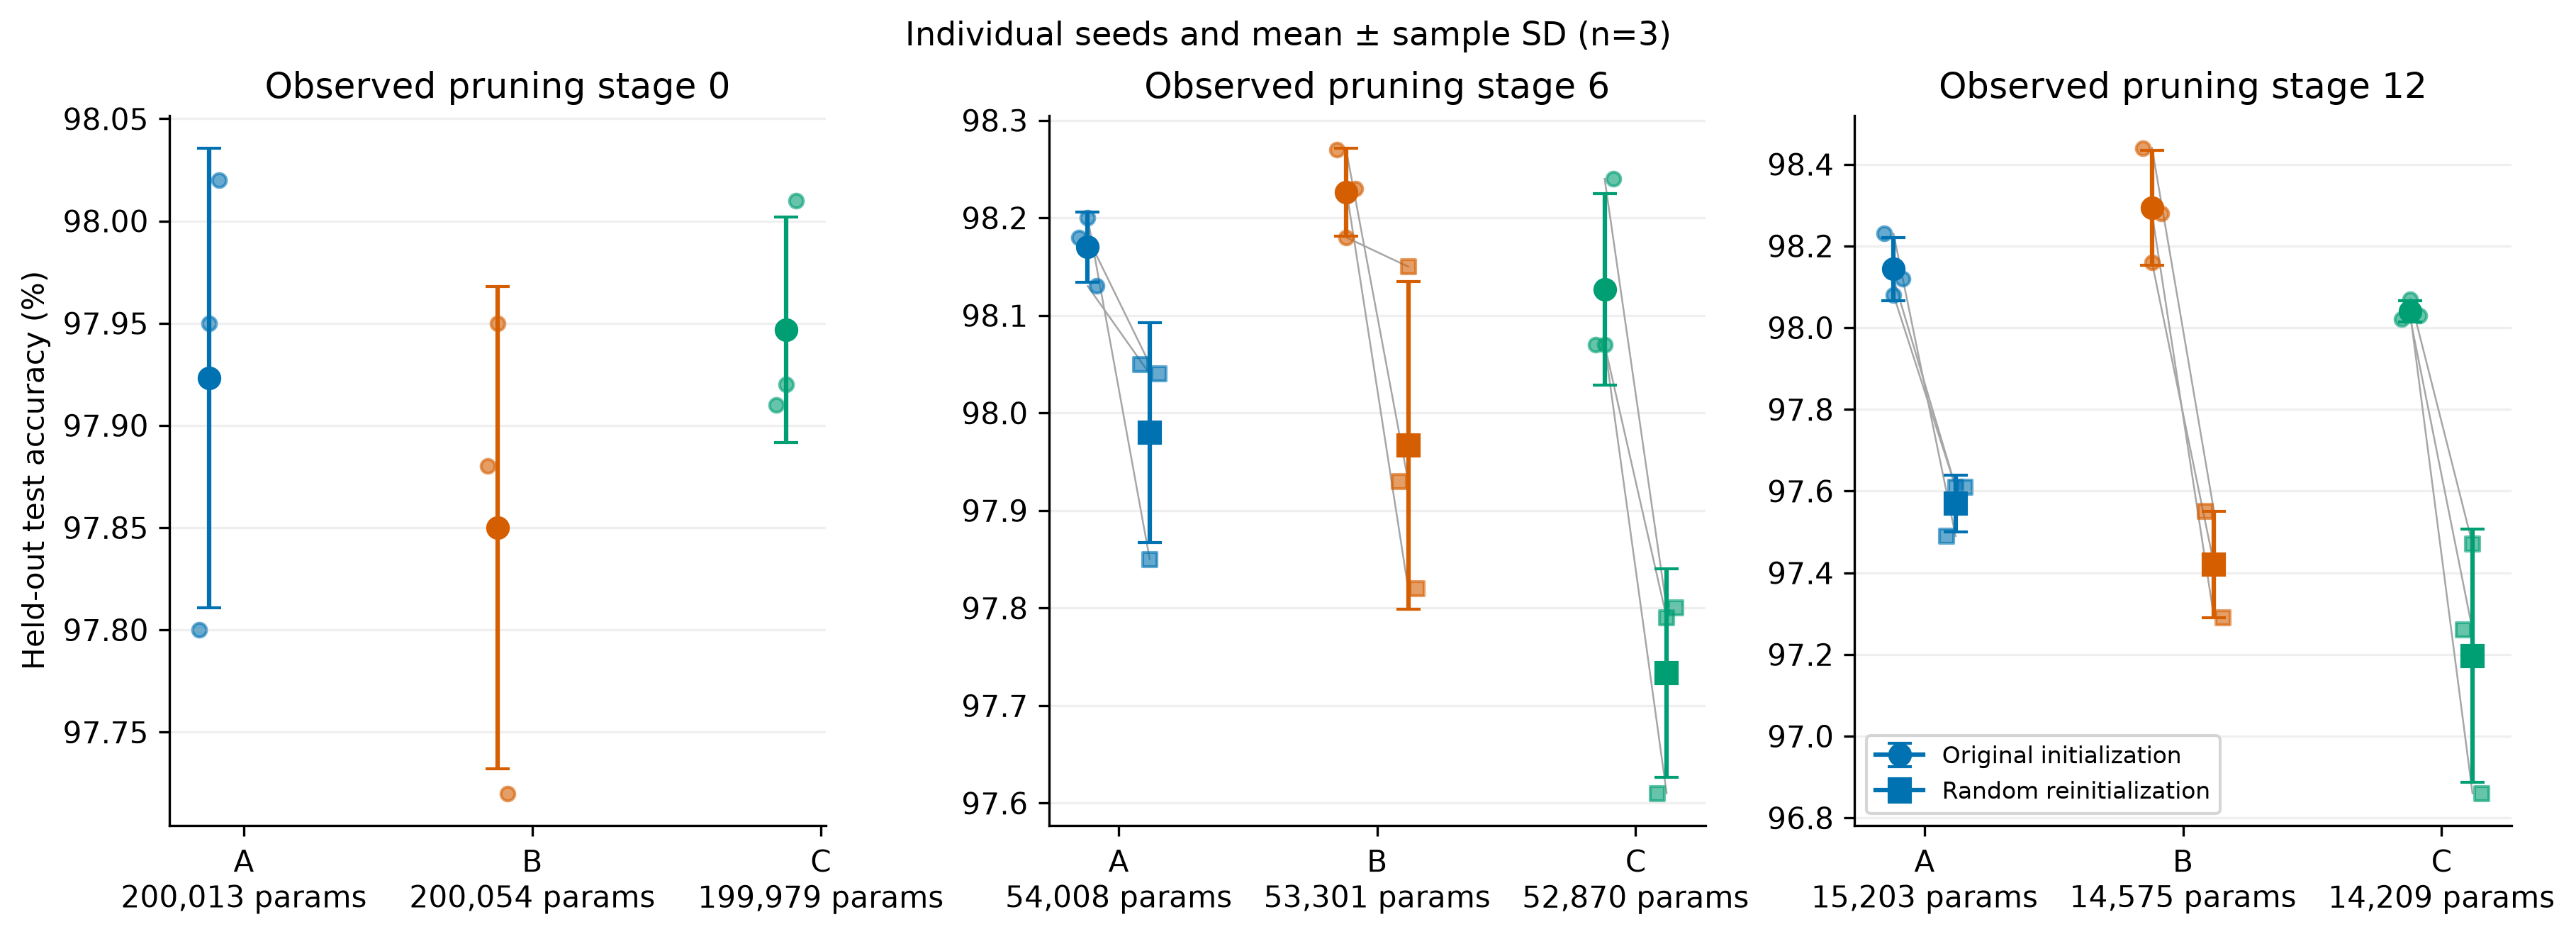

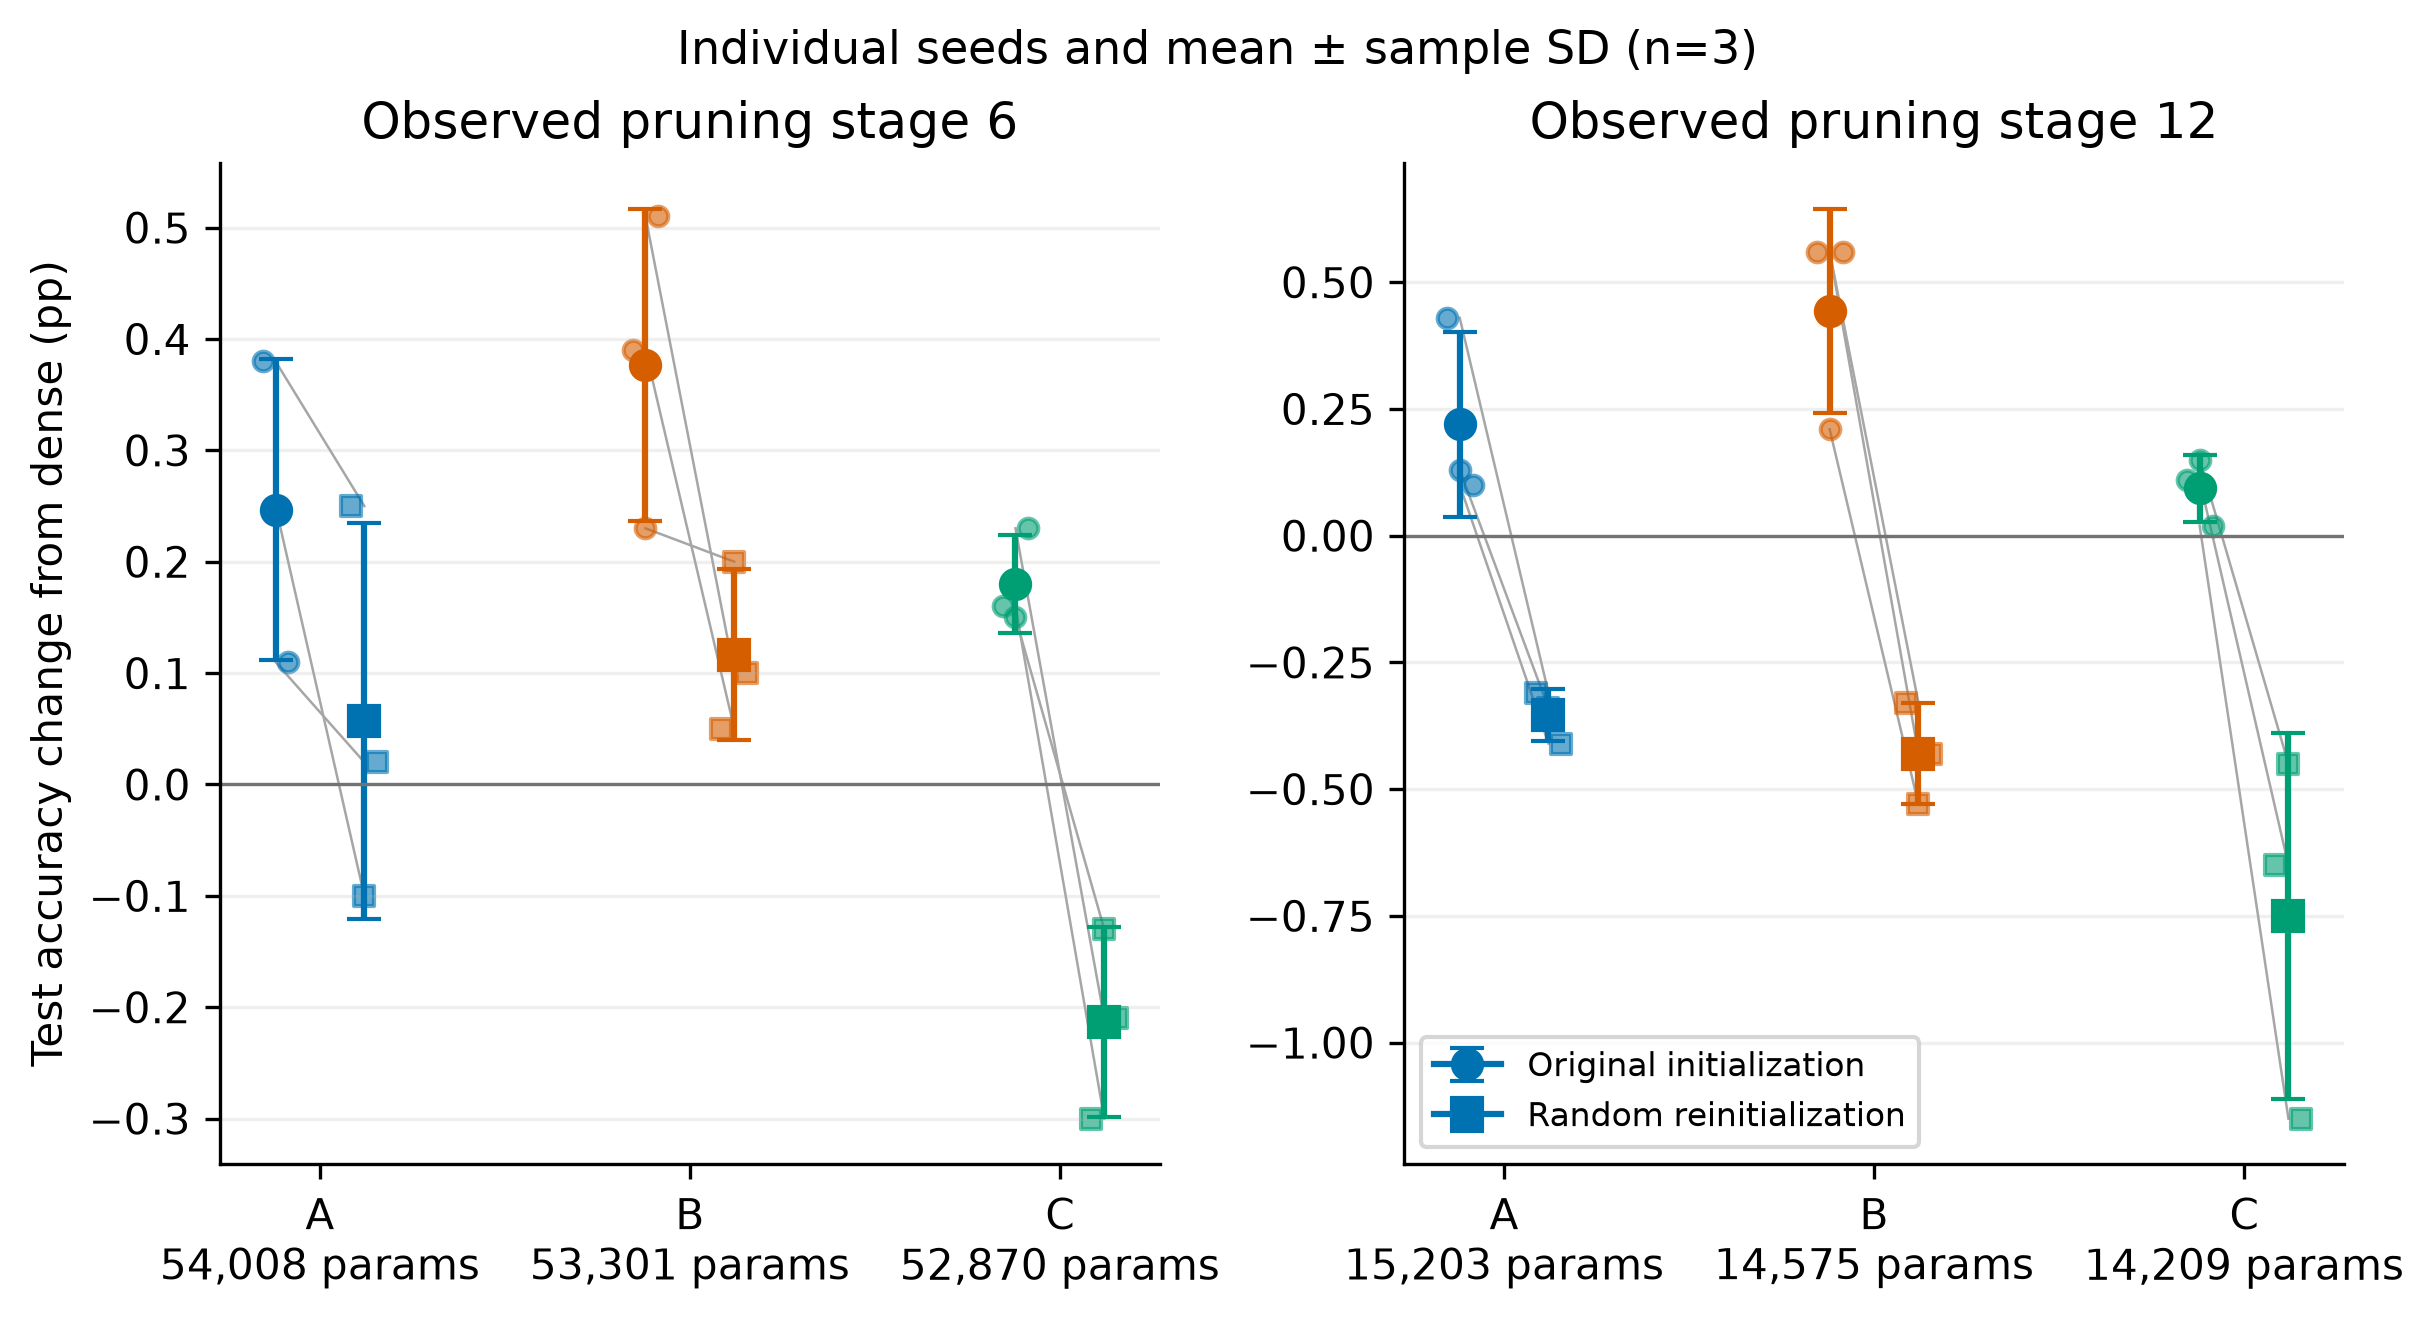

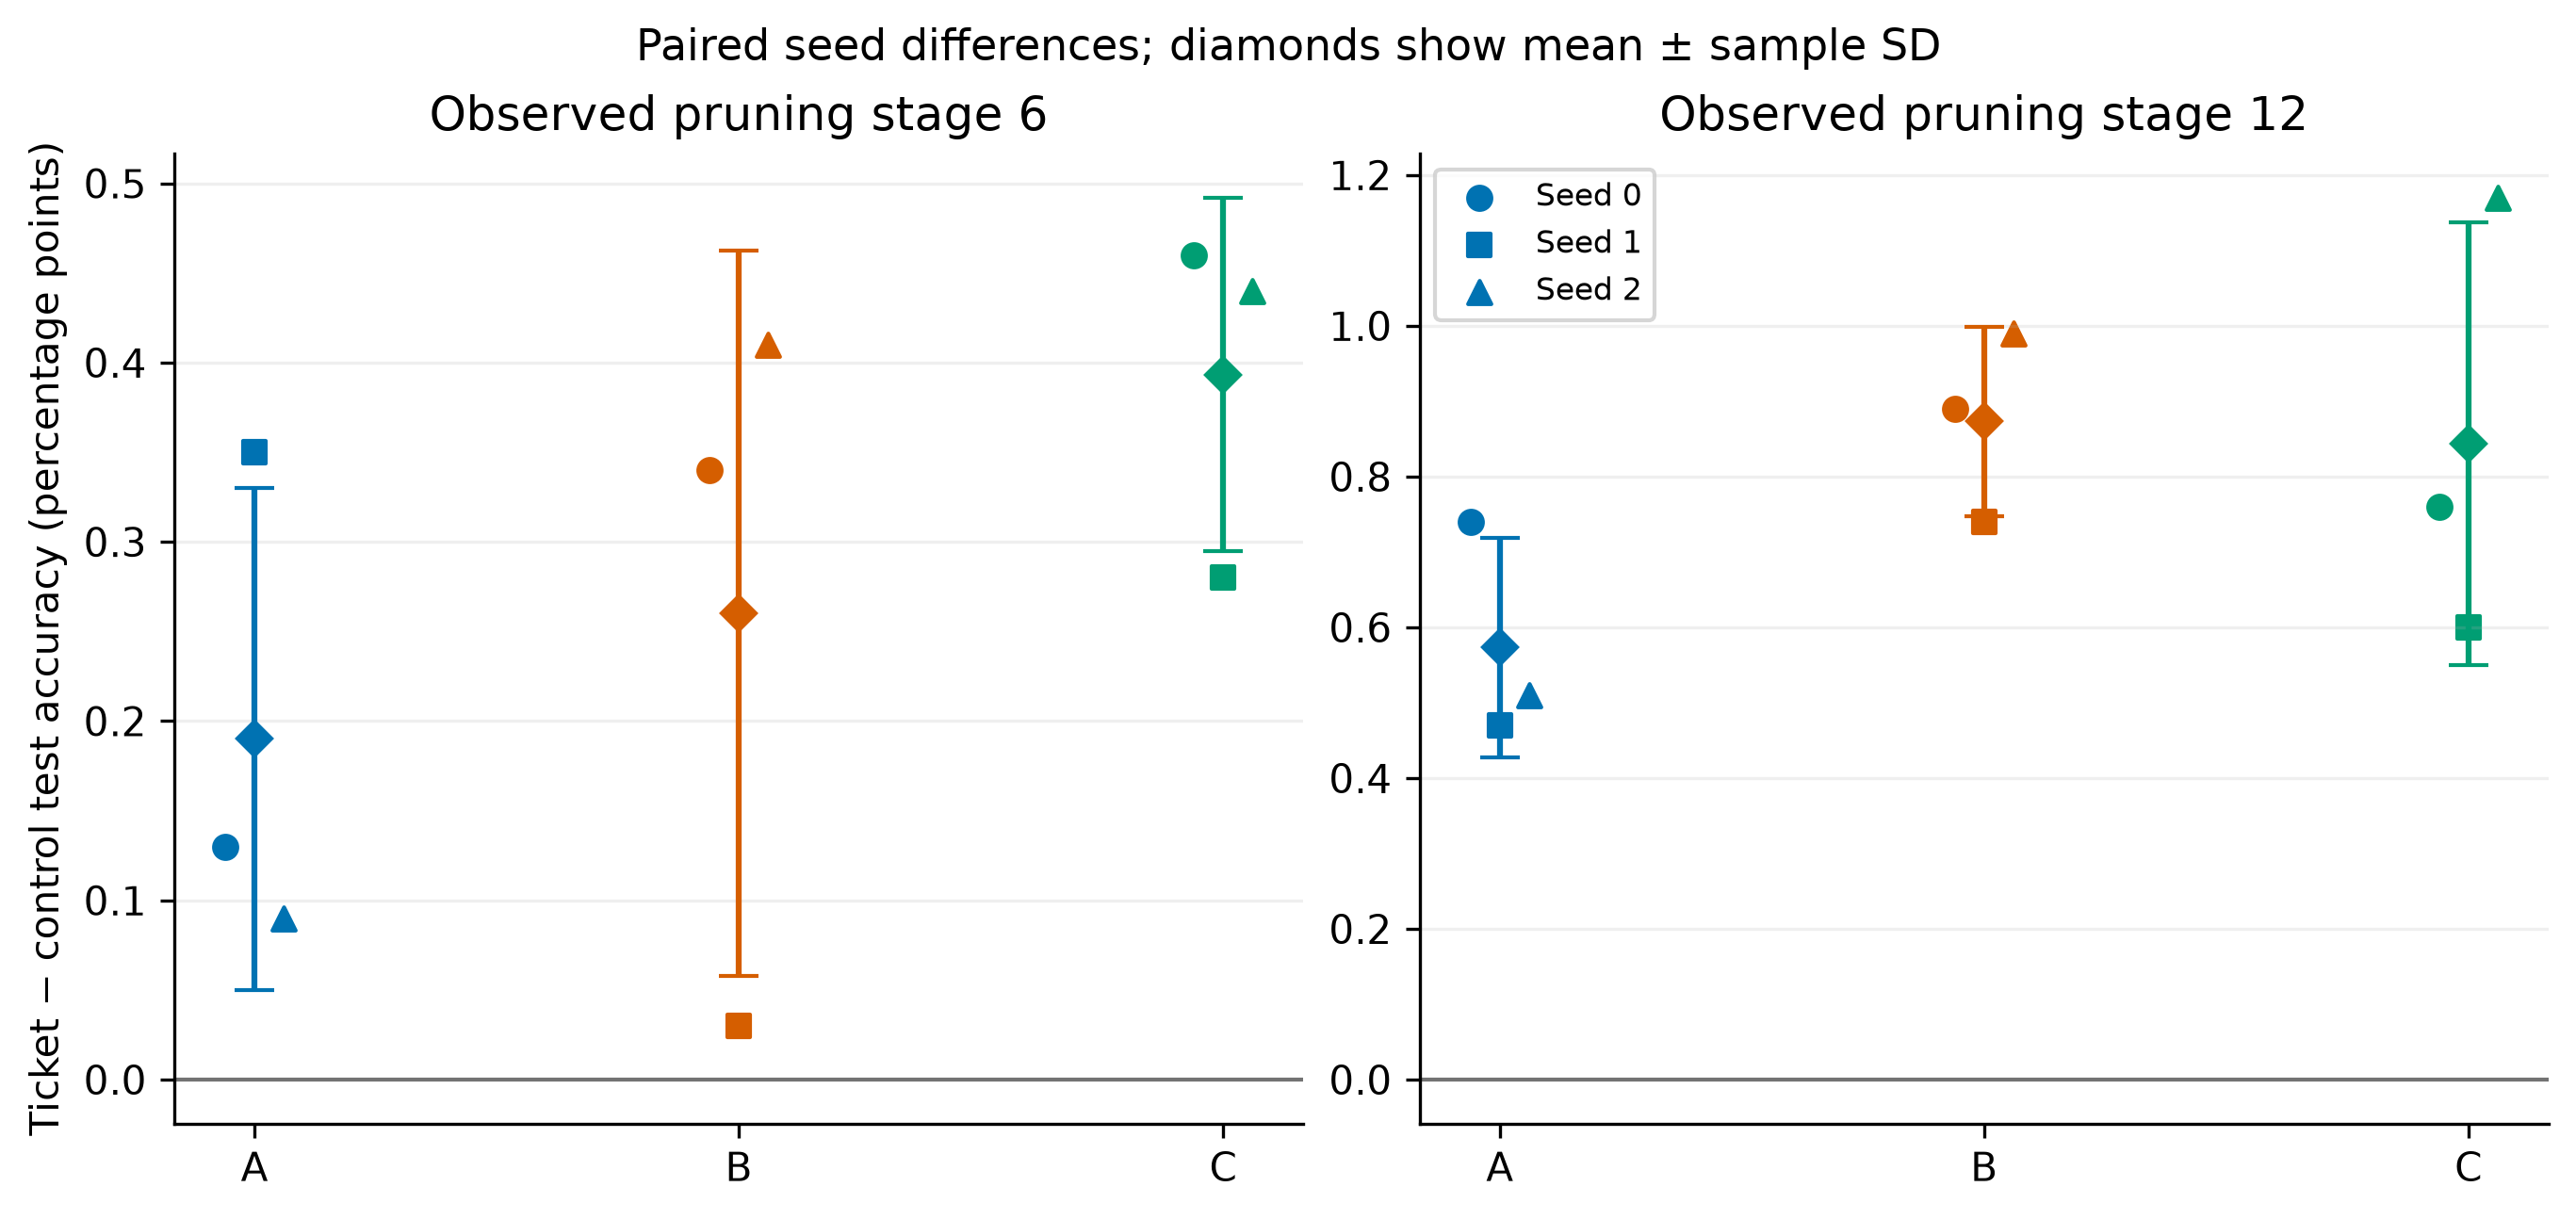

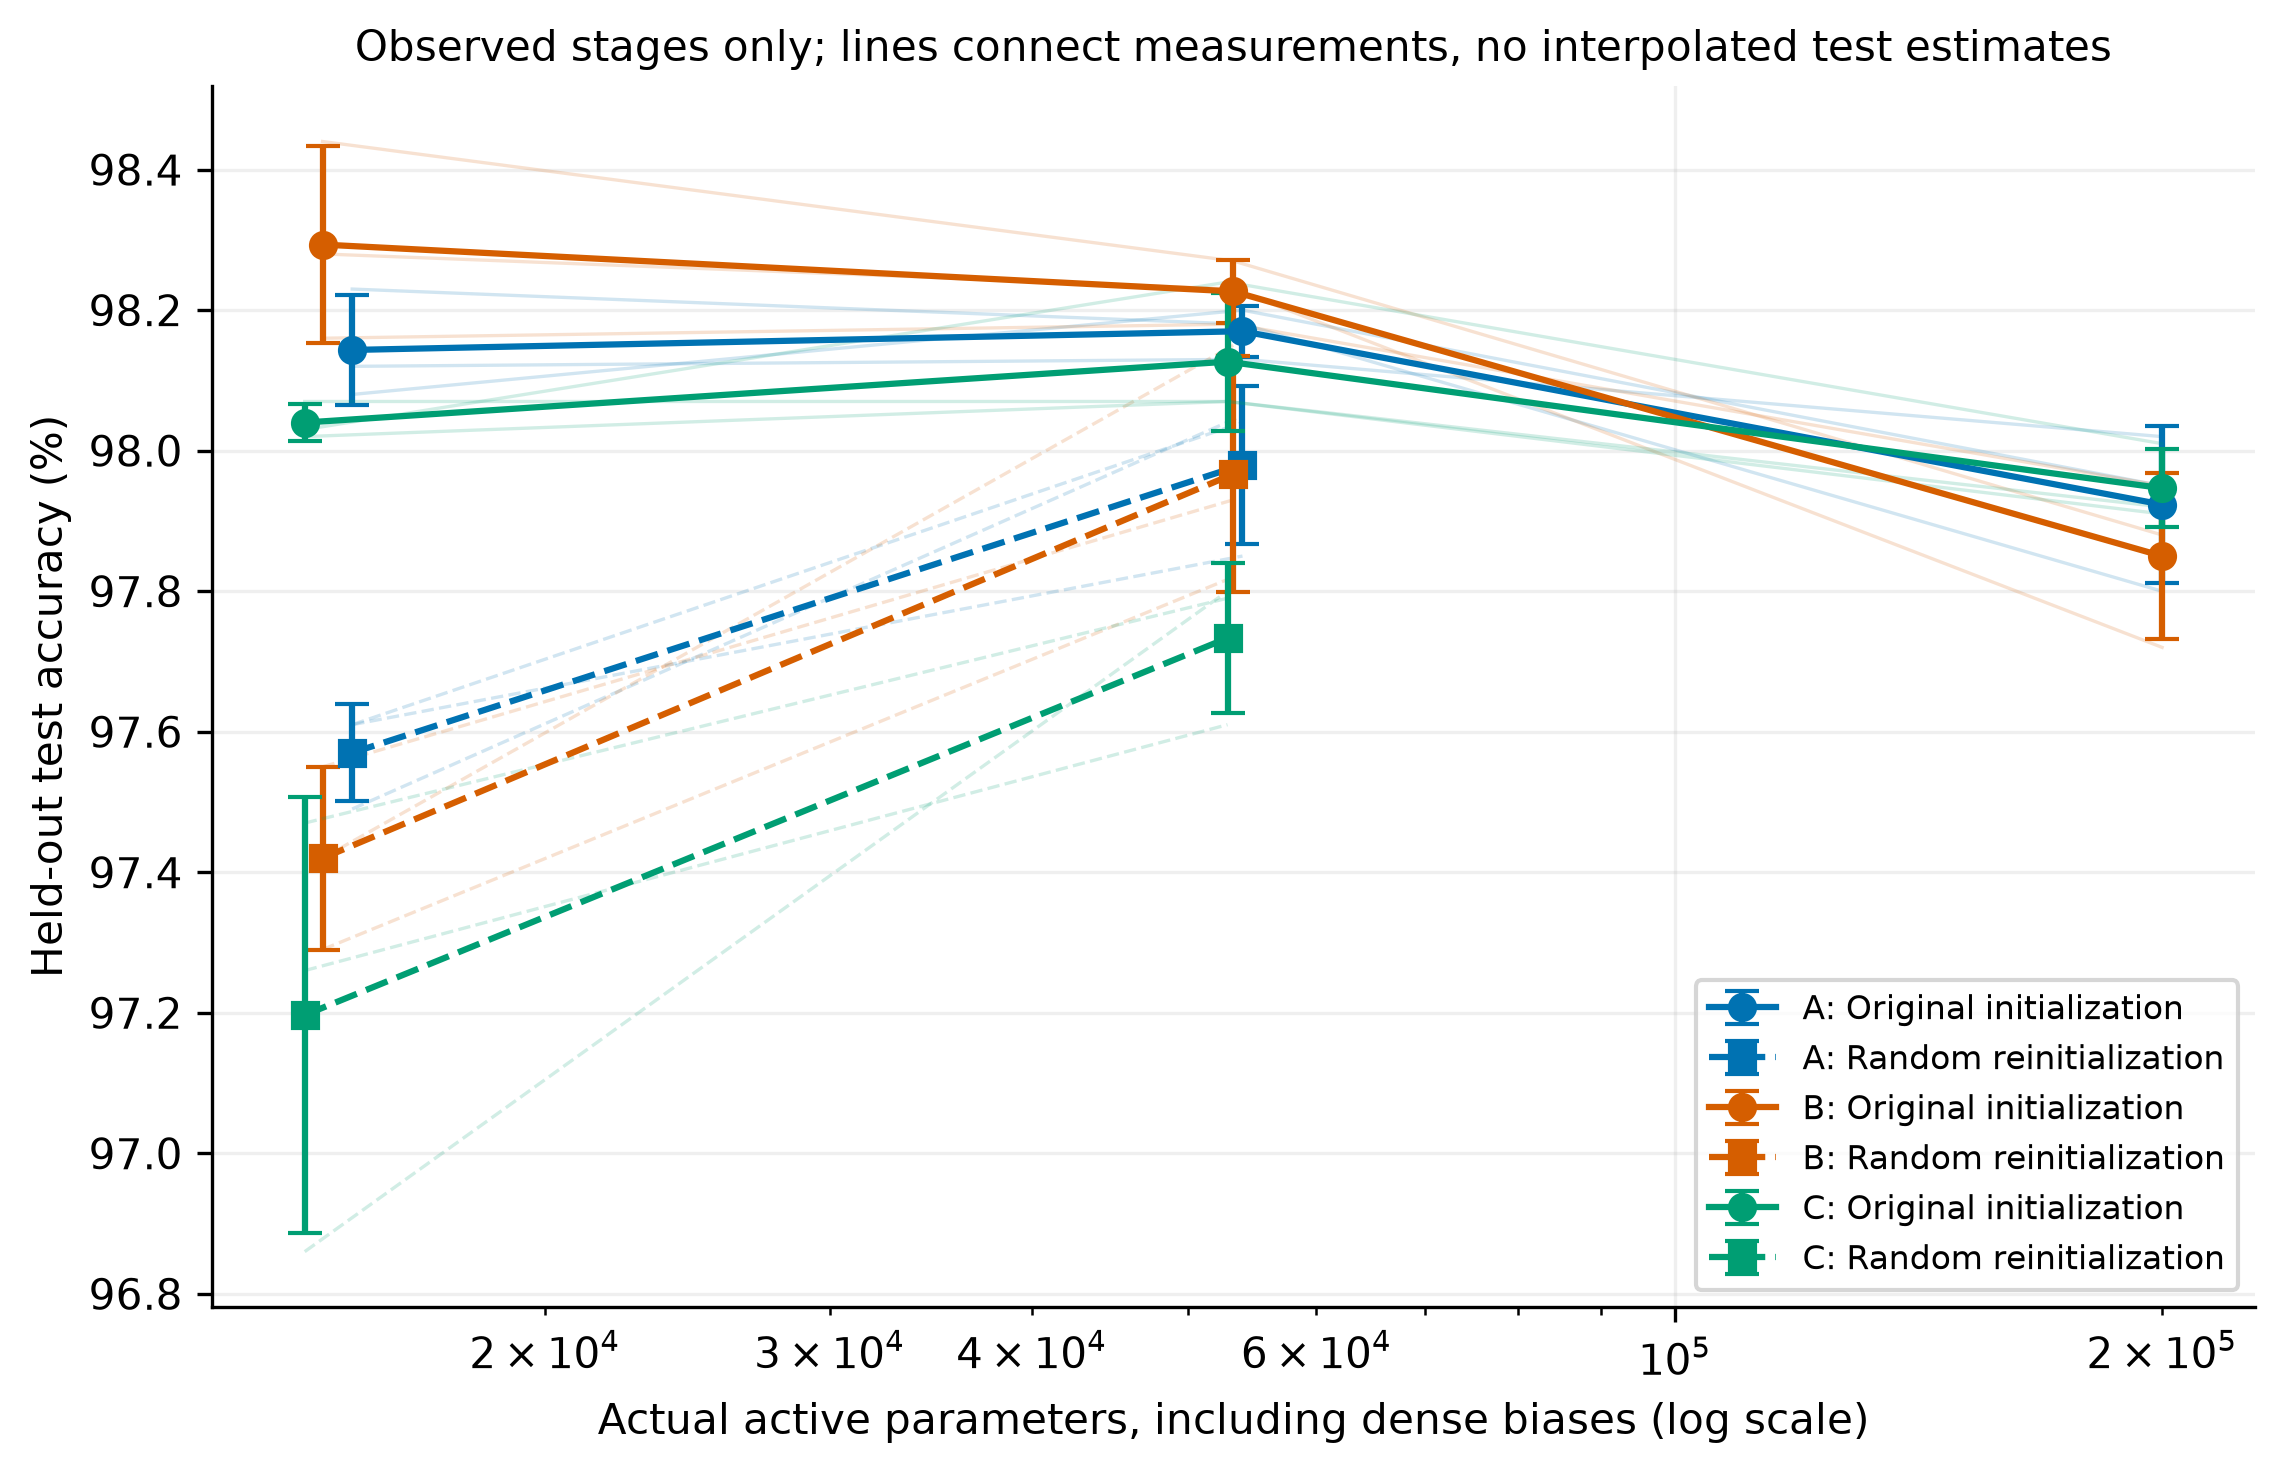

In [2]:
from stage4_test_analysis import analyze
individual,pairs,summary,paired_summary=analyze()
display(individual[['architecture','seed','stage','condition','selected_iteration','test_accuracy','test_accuracy_change_pp','remaining_parameters','sparsity','parameter_sparsity']])
display(summary)
display(paired_summary)
for name in ('test_accuracy_by_observed_stage','dense_relative_test_accuracy','paired_test_accuracy_differences','test_accuracy_vs_remaining_parameters'):
    display(Image(filename=str(REPORT/'figures'/f'{name}.png')))

In [3]:
from checkpoints import sha256
for row in gate['records']:
    assert sha256(ROOT/row['checkpoint'])==row['checkpoint_sha256']
assert preserve_previous()==json.loads((REPORT/'verification.json').read_text())['prior_files_unchanged']
tests=subprocess.run([sys.executable,'-m','pytest','-q'],cwd=ROOT,text=True,capture_output=True)
(REPORT/'tests.txt').write_text(tests.stdout+tests.stderr)
print(tests.stdout)
assert tests.returncode==0,tests.stderr
display(Markdown((REPORT/'reproducibility.md').read_text()))
display(Markdown((REPORT/'findings.md').read_text()))

........................................................................ [ 72%]
............................                                             [100%]
100 passed in 6.91s



# Verification and reproducibility

- Exactly 27 ticket replays: A/B/C × seeds 0/1/2 × observed stages 0/6/12.
- Exactly 18 saved Stage 4A controls: A/B/C × seeds 0/1/2 × stages 6/12.
- All **45** states passed validation before test evaluation; no failed checkpoint was tested.
- Predeclared absolute tolerance: validation loss **1e-08**, accuracy **1e-12**; no relative tolerance. With 5,000 validation examples this accuracy tolerance permits no changed total classification count.
- Maximum observed loss discrepancy **9.02e-17**; maximum accuracy discrepancy **0**.
- Every replay's entire 100-step validation-history prefix matched historical losses/accuracies within these tolerances, including C seed 0's original fine diagnostic trace. Its old 500-step primary eligibility flags do not alter the recovered 100-step selected iteration.
- Starts equal the saved original initialization with the exact saved mask applied, including restored biases. Source start/final masks match; original commit checksums and frozen source/software versions were checked.
- All reconstructed checkpoint tensors were checked for finite values, masked zeros, and lossless save/reload. Mask persistence was checked at every replay validation point and again after loading selected states.
- Actual replay sample-fetch hashes, sample counts and final DataLoader-generator states matched index-only reconstruction of the original seed/split/loader protocol. Historical Stage 3 fetch hashes were not recorded; the claim is protocol reconstruction, not comparison to an unavailable historical trace.
- Fresh Adam, learning rate .0012, batch size 60, split seed 42, CPU/one Torch thread, exact saved split, unchanged Gaussian-Glorot original starts; original core source SHA256 and versions are in `protocol.lock.json`.
- Test data uses the original [0,1] pixel transform, no augmentation, all 10,000 examples, and the existing example-weighted evaluation code. Test loss is reported as an additional measurement; it did not select weights.
- **1268** previous results/report/notebook files retain their SHA256 hashes. `previous_results_snapshot.json` is the preservation manifest. New recovered states live only under `reports/stage4_test/replays/`.
- All new selected-state checksums are in `validation_gate.json` and `verification.json`. Complete replay markers are written after verification; cached complete replays are checksum-checked and skipped. Cached test results are reused for the same checkpoint set, without reselection.
- Wall-clock replay/verification/test execution: **4.21 minutes**, up to three replay worker processes. Package versions match the historical run; cross-platform bitwise replay is not promised. The notebook and spawn-safe runner use pathlib and workers=0 for data loading for Windows/macOS portability.

Reproduce or validate artifacts with `.venv/bin/python stage4_test_runner.py --workers 3`, then `.venv/bin/python stage4_test_analysis.py`, or execute `stage4_test.ipynb`. Completed checkpoints/results are reused. Run `.venv/bin/python -m pytest -q` for unit and synthetic integration tests; test results are saved in `tests.txt`. No synthetic test is an additional MNIST training experiment.


# Final held-out research findings

All 27 preselected ticket states were reconstructed only to their recorded minimum-validation-loss iteration. All 27 tickets and 18 saved control states passed validation before any held-out evaluation. The 45 selected states were evaluated on all 10,000 MNIST test images; no test-based selection or hyperparameter changes were made.

## Test accuracy and preservation of each seed's dense baseline

Mean ± sample standard deviation across three model seeds. Accuracy is percent; dense-relative changes are percentage points. Random controls use the corresponding original architecture/seed dense baseline, not a separately trained random dense model.

| Architecture | Observed stage | Initialization | Test accuracy (%) | Change from dense (pp) |
|---|---:|---|---:|---:|
| A | 0 | Original initialization | 97.923 ± 0.112 | +0.000 ± 0.000 |
| A | 6 | Original initialization | 98.170 ± 0.036 | +0.247 ± 0.135 |
| A | 6 | Random reinitialization | 97.980 ± 0.113 | +0.057 ± 0.178 |
| A | 12 | Original initialization | 98.143 ± 0.078 | +0.220 ± 0.182 |
| A | 12 | Random reinitialization | 97.570 ± 0.069 | -0.353 ± 0.051 |
| B | 0 | Original initialization | 97.850 ± 0.118 | +0.000 ± 0.000 |
| B | 6 | Original initialization | 98.227 ± 0.045 | +0.377 ± 0.140 |
| B | 6 | Random reinitialization | 97.967 ± 0.168 | +0.117 ± 0.076 |
| B | 12 | Original initialization | 98.293 ± 0.140 | +0.443 ± 0.202 |
| B | 12 | Random reinitialization | 97.420 ± 0.130 | -0.430 ± 0.100 |
| C | 0 | Original initialization | 97.947 ± 0.055 | +0.000 ± 0.000 |
| C | 6 | Original initialization | 98.127 ± 0.098 | +0.180 ± 0.044 |
| C | 6 | Random reinitialization | 97.733 ± 0.107 | -0.213 ± 0.085 |
| C | 12 | Original initialization | 98.040 ± 0.026 | +0.093 ± 0.067 |
| C | 12 | Random reinitialization | 97.197 ± 0.310 | -0.750 ± 0.361 |

## Same-mask paired initialization comparison

Positive ticket-minus-control differences favor original initialization. Differences are paired before computing sample SD.

| Architecture | Observed stage | Ticket − control test accuracy (pp) | Ticket wins |
|---|---:|---:|---:|
| A | 6 | +0.190 ± 0.140 | 3/3 |
| A | 12 | +0.573 ± 0.146 | 3/3 |
| B | 6 | +0.260 ± 0.202 | 3/3 |
| B | 12 | +0.873 ± 0.126 | 3/3 |
| C | 6 | +0.393 ± 0.099 | 3/3 |
| C | 12 | +0.843 ± 0.294 | 3/3 |

Original tickets had higher test accuracy in **18/18** pairs, lower accuracy in **0/18**, with **0/18** ties. At stage 12 they won **9/9** pairs. The greatest mean stage-12 initialization advantage was **B: +0.873 ± 0.126 pp**. Largest per-seed high-sparsity gaps: seed 0: B, seed 1: B, seed 2: C.

## Relation to Stage 3 and Stage 4A

At stage 6, B had the highest mean dense-relative test accuracy change (+0.377 pp). At stage 12, B had the highest mean dense-relative test accuracy change (+0.443 pp). B's stage-12 individual dense-relative changes were seed 0: +0.560 pp; seed 1: +0.210 pp; seed 2: +0.560 pp. Assessing preservation relative to dense and assessing absolute accuracy are different comparisons; the per-seed and aggregate tables report both. B led dense-relative preservation in 2/3 seeds at stage 6 and 3/3 at stage 12. All nine stage-12 original tickets exceeded their own dense test accuracy, so these are improvements rather than degradation on this held-out set. B's larger relative gain also reflects its somewhat lower dense baseline; both absolute accuracy and change should be considered.

C's claim to the largest initialization sensitivity **does not hold uniformly on test**. At stage 6 C has the largest mean gap (+0.393 pp). At stage 12, B's mean gap (+0.873 ± 0.126 pp) is slightly larger than C's (+0.843 ± 0.294 pp), reversing the Stage 4A validation mean ordering. This small B–C difference is not evidence of statistical superiority. A larger ticket–control advantage measures initialization sensitivity, not architectural superiority: B has the highest original-ticket mean accuracy at stage 12, while A has the highest random-control mean accuracy there. The ranking therefore depends on initialization condition as well as sparsity and metric.

`validation_test_comparison.csv` and the paired CSV preserve both validation and held-out measurements, allowing direct comparison without treating agreement as a statistical test. Conclusions depend on sparsity level, initialization condition, and whether the metric is absolute accuracy, dense-relative change, or paired initialization benefit. They are descriptive: three model seeds do not establish statistical significance, and all seeds share one dataset split and one test set.

## Active parameters and sparsity

Counts are identical between each ticket and its paired control. These are mask-active positions, not counts of numerically nonzero weights.

| Architecture | Observed stage | Active parameters (including biases) | Weight sparsity | Parameter sparsity |
|---|---:|---:|---:|---:|
| A | 0 | 200,013 | 0.000% | 0.000% |
| A | 6 | 54,008 | 73.215% | 72.998% |
| A | 12 | 15,203 | 92.674% | 92.399% |
| B | 0 | 200,054 | 0.000% | 0.000% |
| B | 6 | 53,301 | 73.509% | 73.357% |
| B | 12 | 14,575 | 92.907% | 92.714% |
| C | 0 | 199,979 | 0.000% | 0.000% |
| C | 6 | 52,870 | 73.679% | 73.562% |
| C | 12 | 14,209 | 93.043% | 92.895% |

## Scope and limitations

Only **observed pruning stages 0, 6 and 12** were evaluated. The prior Stage 3 **16k/20k validation estimates were interpolations** between observed points; they are neither measured models nor test-set results. Actual active parameter counts differ between architectures at the same pruning stage. Counts include unpruned biases; weight sparsity excludes biases, while parameter sparsity includes them. These denominators are separately recorded in CSVs.

All original experiments used **10,000 fixed updates per stage rather than the original paper's 50,000**. Replays stopped only at preselected iterations to recover missing states; they did not change the original training budget, prune models again, or select new checkpoints. Controls were also trained for 10,000 updates. In Stage 4A, 16/18 control minima occurred within the last 20% of that budget, so random reinitialization may have been training-budget limited. These results do not establish asymptotic inferiority of random initialization or a universally superior hidden-layer ratio.

Experimental execution is complete. No further training experiments are automatically launched.


The experimental phase ends here. Checkpoints were selected using validation only. No additional training experiment is launched. Random controls may have been limited by the fixed 10,000-update budget; n=3 and one shared dataset split support descriptive comparisons, not claims of statistical significance.